# Parte 3
## Exploración y características relevantes

Este notebook consume exclusivamente `df_master_pre_modelado.csv`, generado por `EDA_corregido_Gran_Concepcion.ipynb`.

**Pregunta operativa:** ¿Qué tan bien se pueden estimar las emisiones (toneladas) de un grupo de vehículos en una comuna del Gran Concepción a partir de la comuna, el grupo vehicular y la composición de los registros de permisos de circulación disponibles?

**No es un pronóstico temporal.** `año` se utiliza para integrar y auditar cobertura, pero no será predictor. La unidad de análisis es una fila por año–comuna–grupo vehicular y contaminante.

**Precaución:** las variables de permisos son conteos de registros administrativos, no necesariamente vehículos únicos. Solo deben utilizarse si están disponibles en el momento de la estimación. No se permite usar `registros_ruea` como predictor porque procede de la misma fuente y del proceso de construcción del objetivo.

### 3.1 Carga, selección del contaminante y control de calidad

In [1]:
# [Celda 3]
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, chi2_contingency
from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid")
RUTA_DATASET = Path("df_master_pre_modelado.csv")
CARPETA_FIGURAS = Path("figs")
CARPETA_FIGURAS.mkdir(exist_ok=True)

if not RUTA_DATASET.exists():
    raise FileNotFoundError("Ejecuta primero el notebook EDA y genera df_master_pre_modelado.csv.")
df = pd.read_csv(RUTA_DATASET)
df.columns = df.columns.str.strip()

OBJETIVO = "emisiones_agregadas_toneladas"
if OBJETIVO not in df:
    raise ValueError(f"No está el objetivo {OBJETIVO}. Columnas: {df.columns.tolist()}")

# Si RUEA contiene varios contaminantes, seleccionar uno explícitamente.
COL_CONT = next((c for c in df.columns if "contamin" in c or "sustancia" in c), None)
CONTAMINANTE_ELEGIDO = "Dióxido de carbono (CO2)"  # Se define un contaminante específico para evitar el error
if COL_CONT:
    valores = df[COL_CONT].dropna().astype(str).unique().tolist()
    print("Contaminantes disponibles:", valores)
    if len(valores) > 1 and CONTAMINANTE_ELEGIDO is None:
        raise ValueError("Hay más de un contaminante. Define CONTAMINANTE_ELEGIDO antes de modelar; no se deben sumar sustancias distintas.")
    if CONTAMINANTE_ELEGIDO is not None:
        df = df[df[COL_CONT].astype(str) == str(CONTAMINANTE_ELEGIDO)].copy()

claves = ["año", "comuna_norm", "grupo_vehiculo"]
faltan = [c for c in claves if c not in df]
if faltan: raise ValueError(f"Faltan columnas de la clave: {faltan}")
df[OBJETIVO] = pd.to_numeric(df[OBJETIVO], errors="coerce")
df = df.dropna(subset=[OBJETIVO, "comuna_norm", "grupo_vehiculo"]).copy()

print("Filas:", len(df), "| columnas:", len(df.columns))
print("Duplicados por clave:", df.duplicated(claves).sum())
if df.duplicated(claves).any():
    raise ValueError("Hay duplicados año-comuna-grupo; revisa la agregación en el EDA.")
display(df.head())

Contaminantes disponibles: ['Compuestos Orgánicos Volátiles', 'Dibenzoparadioxinas policloradas y furanos (PCDD/F)', 'Dióxido de azufre (SO2)', 'Dióxido de carbono (CO2)', 'MP10', 'MP2,5', 'Material particulado', 'Mercurio', 'Metano (CH4)', 'Monóxido de carbono', 'NOx', 'Nitrógeno amoniacal (o NH3)', 'Oxido Nitroso']
Filas: 110 | columnas: 15
Duplicados por clave: 0


,año,comuna_norm,grupo_vehiculo,contaminantes,emisiones_agregadas_toneladas,registros_ruea,registros_permiso,permisos_combustible_bencina,permisos_combustible_diesel,permisos_combustible_electrico,permisos_combustible_gas,registros_catalitico,permisos_cataliticos,permisos_no_cataliticos,tiene_registro_permiso
3,2022,chiguayante,Buses,Dióxido de carbono (CO2),1.700268e+10,8,663.0,224.0,439.0,0.0,0.0,663.0,663.0,0.0,True
16,2022,chiguayante,Camiones,Dióxido de carbono (CO2),2.906130e+10,14,441.0,64.0,377.0,0.0,0.0,441.0,419.0,22.0,True
29,2022,chiguayante,Comerciales livianos,Dióxido de carbono (CO2),2.938307e+10,15,6663.0,2380.0,4283.0,0.0,0.0,6663.0,6534.0,129.0,True
42,2022,chiguayante,Livianos pasajeros,Dióxido de carbono (CO2),9.177986e+10,76,26591.0,24128.0,2401.0,62.0,0.0,26591.0,26332.0,259.0,True
55,2022,chiguayante,Motocicletas,Dióxido de carbono (CO2),1.407654e+10,12,751.0,747.0,0.0,4.0,0.0,751.0,745.0,6.0,True


In [2]:
# [Celda 4]
# Calidad del objetivo y disponibilidad de columnas
n_total = len(df)
n_nulos_y = int(df[OBJETIVO].isna().sum())
print(f"Objetivo: n={n_total-n_nulos_y}/{n_total}; nulos={n_nulos_y} ({n_nulos_y/max(n_total,1):.1%})")
print(f"Mediana={df[OBJETIVO].median():.4g} t; media={df[OBJETIVO].mean():.4g} t; "
      f"mín={df[OBJETIVO].min():.4g} t; máx={df[OBJETIVO].max():.4g} t")
display(df.isna().sum().to_frame("n_nulos").assign(pct=lambda x: 100*x.n_nulos/max(len(df),1)))
display(df.groupby("año")[OBJETIVO].agg(n="count", media="mean", mediana="median"))

Objetivo: n=110/110; nulos=0 (0.0%)
Mediana=1355 t; media=2.03e+10 t; mín=0 t; máx=1.509e+11 t


,n_nulos,pct
año,0,0.000000
comuna_norm,0,0.000000
grupo_vehiculo,0,0.000000
contaminantes,0,0.000000
emisiones_agregadas_toneladas,0,0.000000
registros_ruea,0,0.000000
registros_permiso,1,0.909091
permisos_combustible_bencina,1,0.909091
permisos_combustible_diesel,1,0.909091
permisos_combustible_electrico,1,0.909091


,n,media,mediana
año,,,
2022,50,4.466239e+10,3.174294e+10
2023,60,5.357303e+02,3.229892e+02


### 3.2 Bitácora de EDA
Cada hallazgo queda calculado con cifra y `n`, figura guardada, celda generadora, vínculo con la pregunta y decisión. Las figuras declaran unidad, escala y celda.

**Numeración de celdas:** cada celda de código lleva en su primera línea la etiqueta `# [Celda N]`, donde N es su posición en el notebook (contando también las celdas de texto). Las figuras, la bitácora y la ficha citan esa numeración.

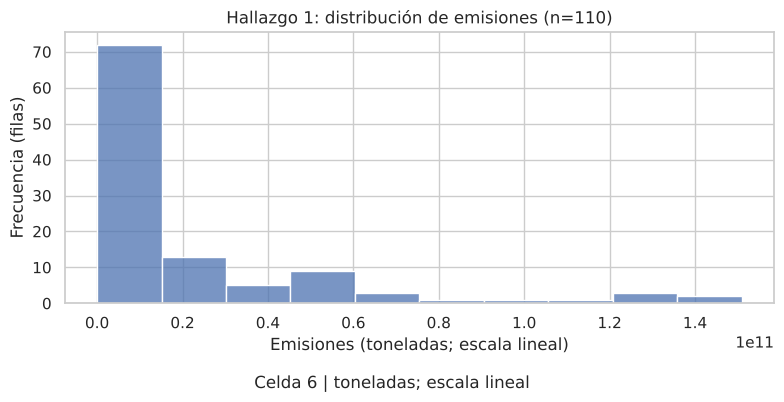

In [3]:
# [Celda 6]
# Hallazgo 1 — distribución del objetivo (celda 6)
y = df[OBJETIVO].dropna()
fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(y, bins=min(20, max(5, int(np.sqrt(len(y))))), ax=ax)
ax.set(title=f"Hallazgo 1: distribución de emisiones (n={len(y)})",
       xlabel="Emisiones (toneladas; escala lineal)", ylabel="Frecuencia (filas)")
fig.text(.5,.01,"Celda 6 | toneladas; escala lineal",ha="center")
fig.tight_layout(rect=[0,.05,1,1]); fig.savefig(CARPETA_FIGURAS/"01_objetivo.png",dpi=160); plt.show()
# print(f"H1: n={len(y)}, nulos={df[OBJETIVO].isna().sum()}, mediana={y.median():.4g} t, "
#       f"media={y.mean():.4g} t, rango=[{y.min():.4g}, {y.max():.4g}] t.")

In [4]:
# [Celda 7]
print(f"""
HALLAZGO 1
============================================================
• Resultado : Objetivo: n={len(y)}, mediana={y.median():.4g} t, media={y.mean():.4g} t; nulos={df[OBJETIVO].isna().sum()}
• Figura    : figs/01_objetivo.png
• Pregunta  : Distribución y escala del resultado
• Decisión  : Definir MAE en toneladas; revisar asimetría y valores extremos.
""")


HALLAZGO 1
• Resultado : Objetivo: n=110, mediana=1355 t, media=2.03e+10 t; nulos=0
• Figura    : figs/01_objetivo.png
• Pregunta  : Distribución y escala del resultado
• Decisión  : Definir MAE en toneladas; revisar asimetría y valores extremos.



,n,media,mediana,total
grupo_vehiculo,,,,
Taxis,10,8.063155e+02,4.355688e+02,8.063155e+03
Motocicletas,20,8.051198e+09,5.193590e+09,1.610240e+11
Buses,20,8.183428e+09,5.356376e+09,1.636686e+11
Camiones,20,1.518058e+10,1.011218e+03,3.036115e+11
Comerciales livianos,20,2.500226e+10,1.469153e+10,5.000452e+11
Livianos pasajeros,20,5.523852e+10,3.646692e+10,1.104770e+12


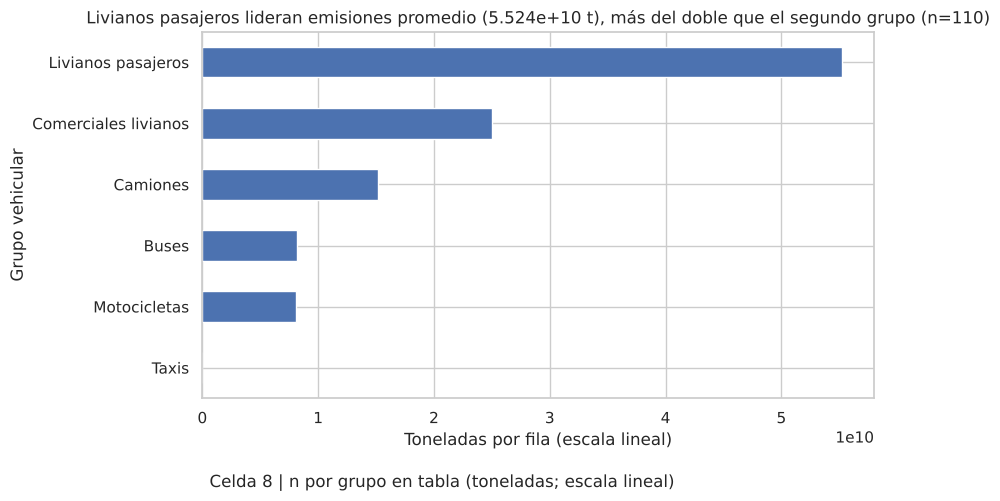

In [5]:
# [Celda 8]
# Hallazgo 2 — emisiones por grupo vehicular (celda 8)
g = df.groupby("grupo_vehiculo")[OBJETIVO].agg(
    n="count", media="mean", mediana="median", total="sum"
).sort_values("media")
display(g)

n_total_h2 = int(g.n.sum())
top_grupo = g.media.idxmax()
top_media = g.media.max()

fig, ax = plt.subplots(figsize=(9, 5))
g["media"].plot(kind="barh", ax=ax)

ax.set(
    title=f"{top_grupo} lideran emisiones promedio ({top_media:.4g} t), más del doble que el segundo grupo (n={n_total_h2})",
    xlabel="Toneladas por fila (escala lineal)",
    ylabel="Grupo vehicular"
)
fig.text(0.5, 0.01, "Celda 8 | n por grupo en tabla (toneladas; escala lineal)", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "02_grupo_vehicular.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos (con el extra estadístico incluido)
h2_resultado = f"{len(g)} grupos; mayor promedio={top_grupo} ({top_media:.4g} t), n={n_total_h2}"
h2_decision = (
    "Mantener grupo_vehiculo como candidata categórica; revisar outliers intra-grupo "
    "(ej. en Camiones la media [1.52e+10 t] supera en 7 órdenes de magnitud a su mediana [1011 t])."
)

hallazgo_2 = [
    "H2",
    h2_resultado,
    "figs/02_grupo_vehicular.png",
    "8",
    "Tipo de vehículo",
    h2_decision
]

In [6]:
# [Celda 9]
print(f"""
HALLAZGO 2
============================================================
• Resultado : {h2_resultado}
• Figura    : figs/02_grupo_vehicular.png
• Pregunta  : Tipo de vehículo
• Decisión  : {h2_decision}
""")


HALLAZGO 2
• Resultado : 6 grupos; mayor promedio=Livianos pasajeros (5.524e+10 t), n=110
• Figura    : figs/02_grupo_vehicular.png
• Pregunta  : Tipo de vehículo
• Decisión  : Mantener grupo_vehiculo como candidata categórica; revisar outliers intra-grupo (ej. en Camiones la media [1.52e+10 t] supera en 7 órdenes de magnitud a su mediana [1011 t]).



,n,media,mediana,total
comuna_norm,,,,
hualqui,11,1.316569e+10,902.112290,1.448226e+11
lota,11,1.539805e+10,408.666027,1.693786e+11
chiguayante,11,1.648213e+10,1293.551521,1.813035e+11
tome,11,1.691465e+10,514.554903,1.860612e+11
penco,11,2.171885e+10,1516.361556,2.389073e+11
talcahuano,11,2.224779e+10,1831.618834,2.447257e+11
hualpen,11,2.328299e+10,2243.353608,2.561129e+11
san pedro de la paz,11,2.359110e+10,2704.280733,2.595021e+11
coronel,11,2.480384e+10,1426.673820,2.728422e+11


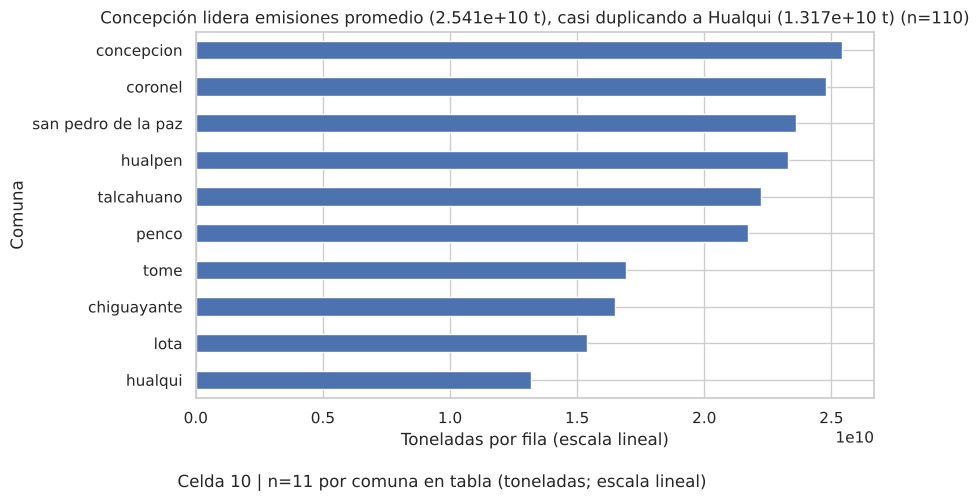

In [7]:
# [Celda 10]
# Hallazgo 3 — diferencias territoriales (celda 10)
c = df.groupby("comuna_norm")[OBJETIVO].agg(
    n="count", media="mean", mediana="median", total="sum"
).sort_values("media")
display(c)

n_total_h3 = int(c.n.sum())
top_comuna = c.media.idxmax()
top_media_c = c.media.max()
min_comuna = c.media.idxmin()
min_media_c = c.media.min()

fig, ax = plt.subplots(figsize=(9, 5))
c["media"].plot(kind="barh", ax=ax)

ax.set(
    title=f"Concepción lidera emisiones promedio ({top_media_c:.4g} t), casi duplicando a Hualqui ({min_media_c:.4g} t) (n={n_total_h3})",
    xlabel="Toneladas por fila (escala lineal)",
    ylabel="Comuna"
)
fig.text(0.5, 0.01, "Celda 10 | n=11 por comuna en tabla (toneladas; escala lineal)", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "03_comuna.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos
h3_resultado = (
    f"{len(c)} comunas balanceadas (n=11 c/u, n={n_total_h3}); mayor promedio={top_comuna} "
    f"({top_media_c:.4g} t) vs menor={min_comuna} ({min_media_c:.4g} t)."
)
h3_decision = (
    "Evaluar comuna como predictor territorial sin interpretar asociación como causal; "
    "verificar si la diferencia responde a mezcla de tipos de vehículo por comuna."
)

hallazgo_3 = [
    "H3",
    h3_resultado,
    "figs/03_comuna.png",
    "10",
    "Territorio",
    h3_decision
]

In [8]:
# [Celda 11]
print(f"""
HALLAZGO 3
============================================================
• Resultado : {h3_resultado}
• Figura    : figs/03_comuna.png
• Pregunta  : Territorio
• Decisión  : {h3_decision}""")


HALLAZGO 3
• Resultado : 10 comunas balanceadas (n=11 c/u, n=110); mayor promedio=concepcion (2.541e+10 t) vs menor=hualqui (1.317e+10 t).
• Figura    : figs/03_comuna.png
• Pregunta  : Territorio
• Decisión  : Evaluar comuna como predictor territorial sin interpretar asociación como causal; verificar si la diferencia responde a mezcla de tipos de vehículo por comuna.


,variable,spearman,n,valores_distintos
0,registros_permiso,0.326072,109,108
1,proporcion_combustible_bencina,0.051489,109,102
2,proporcion_combustible_diesel,-0.034875,109,95
3,proporcion_combustible_electrico,-0.045687,109,53
4,proporcion_combustible_gas,-0.161579,109,10
5,tasa_no_cataliticos,0.180497,109,91


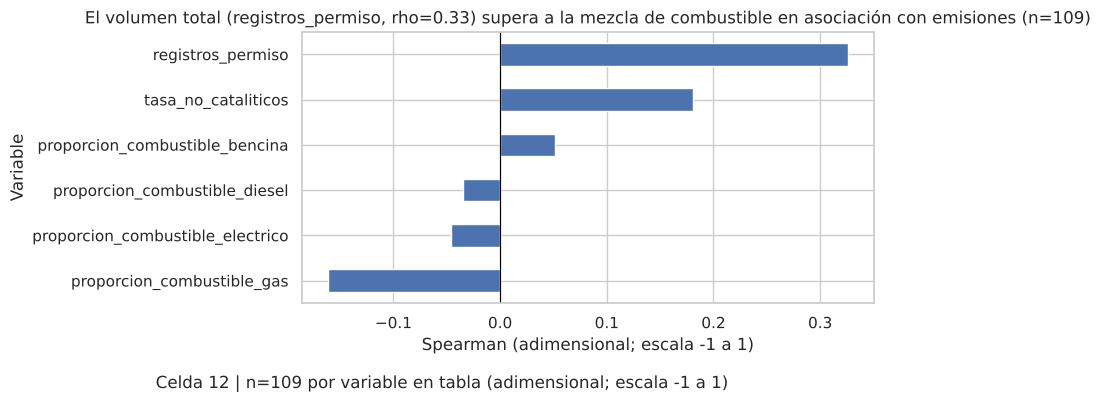

In [9]:
# [Celda 12]
# Hallazgo 4 — relación de conteos de permisos con el objetivo (celda 12)
# Proporciones comparables: evitan introducir simultáneamente conteos redundantes de combustible.
for col in [c for c in df.columns if c.startswith("permisos_combustible_")]:
    df["proporcion_" + col.replace("permisos_combustible_", "combustible_")] = (
        pd.to_numeric(df[col], errors="coerce") /
        pd.to_numeric(df["registros_permiso"], errors="coerce").replace(0, np.nan)
    )
if {"permisos_no_cataliticos", "registros_catalitico"}.issubset(df.columns):
    df["tasa_no_cataliticos"] = (
        pd.to_numeric(df["permisos_no_cataliticos"], errors="coerce") /
        pd.to_numeric(df["registros_catalitico"], errors="coerce").replace(0, np.nan)
    )

conteos = [
    c for c in df.select_dtypes(include=np.number).columns
    if c == "registros_permiso" or c.startswith("proporcion_combustible_")
    or c == "tasa_no_cataliticos"
]

filas = []
for col in conteos:
    par = df[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
    rho = spearmanr(par[col], par[OBJETIVO]).statistic if len(par) >= 3 and par[col].nunique() > 1 else np.nan
    filas.append([col, rho, len(par), par[col].nunique()])

relaciones_num = pd.DataFrame(filas, columns=["variable", "spearman", "n", "valores_distintos"])
display(relaciones_num)

if not relaciones_num.dropna(subset=["spearman"]).empty:
    idx_top = relaciones_num.spearman.abs().idxmax()
    top_var = relaciones_num.loc[idx_top, "variable"]
    top_rho = relaciones_num.loc[idx_top, "spearman"]
    top_n = int(relaciones_num.loc[idx_top, "n"])

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(relaciones_num))))
    relaciones_num.set_index("variable")["spearman"].sort_values().plot(kind="barh", ax=ax)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(
        title=f"El volumen total ({top_var}, rho={top_rho:.2f}) supera a la mezcla de combustible en asociación con emisiones (n={top_n})",
        xlabel="Spearman (adimensional; escala -1 a 1)",
        ylabel="Variable"
    )
    fig.text(0.5, 0.01, f"Celda 12 | n={top_n} por variable en tabla (adimensional; escala -1 a 1)", ha="center")
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(CARPETA_FIGURAS / "04_spearman_permisos.png", dpi=160)
    plt.show()

    h4_resultado = f"{top_var}: rho={top_rho:.3f}, n={top_n} (supera a proporciones de combustible, |rho| <= 0.162)."
else:
    h4_resultado = f"{len(conteos)} conteos; Spearman no calculable"

h4_decision = (
    "Priorizar volumen (registros_permiso) y tasa_no_cataliticos disponibles al estimar; "
    "imputar o filtrar 1 fila con nulo en permisos (n=109 de 110)."
)

hallazgo_4 = [
    "H4",
    h4_resultado,
    "figs/04_spearman_permisos.png",
    "12",
    "Composición y volumen de permisos",
    h4_decision
]

In [10]:
# [Celda 13]
print(f"""
HALLAZGO 4
============================================================
• Resultado : {h4_resultado}
• Figura    : figs/04_spearman_permisos.png
• Pregunta  : Composición y volumen de permisos
• Decisión  : {h4_decision}
""")


HALLAZGO 4
• Resultado : registros_permiso: rho=0.326, n=109 (supera a proporciones de combustible, |rho| <= 0.162).
• Figura    : figs/04_spearman_permisos.png
• Pregunta  : Composición y volumen de permisos
• Decisión  : Priorizar volumen (registros_permiso) y tasa_no_cataliticos disponibles al estimar; imputar o filtrar 1 fila con nulo en permisos (n=109 de 110).



,comuna,variable,spearman,n
0,chiguayante,registros_permiso,0.518182,11
1,chiguayante,proporcion_combustible_bencina,0.000000,11
2,chiguayante,proporcion_combustible_diesel,0.090909,11
3,chiguayante,proporcion_combustible_electrico,0.069395,11
4,chiguayante,proporcion_combustible_gas,-0.500000,11
5,chiguayante,tasa_no_cataliticos,0.311940,11
6,concepcion,registros_permiso,-0.009091,11
7,concepcion,proporcion_combustible_bencina,-0.081818,11
8,concepcion,proporcion_combustible_diesel,0.145455,11
9,concepcion,proporcion_combustible_electrico,-0.237273,11


,comunas_con_datos,mediana_rho,proporcion_mismo_signo
variable,,,
proporcion_combustible_bencina,10,0.000000,0.400000
proporcion_combustible_diesel,10,-0.003040,0.500000
proporcion_combustible_electrico,10,-0.053148,0.500000
proporcion_combustible_gas,6,-0.149595,0.833333
registros_permiso,10,0.298485,0.800000
tasa_no_cataliticos,10,0.278697,0.800000


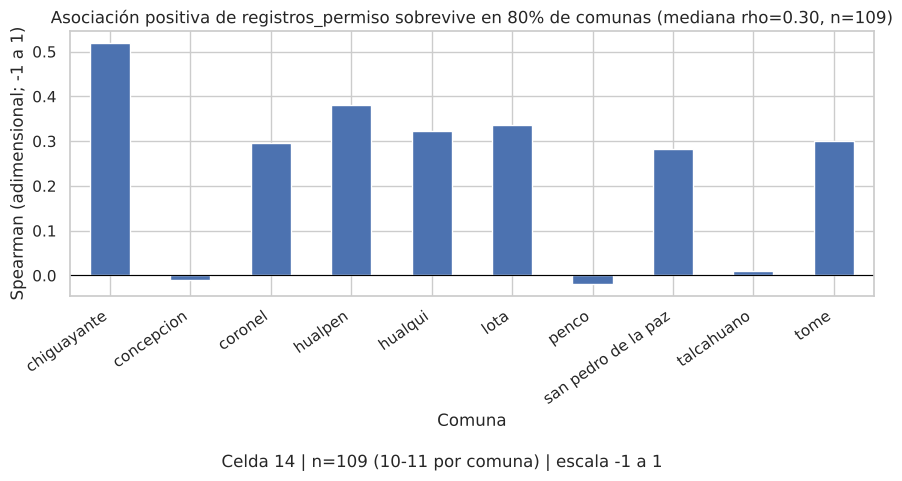

In [11]:
# [Celda 14]
# Hallazgo 5 — segmentación por comuna (celda 14)
segmentos = []
for comuna, sub in df.groupby("comuna_norm"):
    for col in conteos:
        par = sub[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
        if len(par) >= 3 and par[col].nunique() > 1:
            rho = spearmanr(par[col], par[OBJETIVO]).statistic
            segmentos.append([comuna, col, rho, len(par)])

seg = pd.DataFrame(segmentos, columns=["comuna", "variable", "spearman", "n"])
display(seg)

if not seg.empty:
    resumen = seg.groupby("variable").agg(
        comunas_con_datos=("comuna", "nunique"),
        mediana_rho=("spearman", "median"),
        proporcion_mismo_signo=("spearman", lambda x: max((x > 0).mean(), (x < 0).mean()))
    )
    display(resumen)

    # Seleccionamos la variable principal del H4 ('registros_permiso') en vez de la primera alfabética
    col_plot = "registros_permiso" if "registros_permiso" in resumen.index else resumen["mediana_rho"].abs().idxmax()
    sub_plot = seg[seg.variable == col_plot]
    n_real_h5 = int(sub_plot["n"].sum())
    med_rho_plot = resumen.loc[col_plot, "mediana_rho"]
    prop_signo_plot = resumen.loc[col_plot, "proporcion_mismo_signo"] * 100

    fig, ax = plt.subplots(figsize=(9, 4.8))
    sub_plot.plot(x="comuna", y="spearman", kind="bar", legend=False, ax=ax)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(
        title=f"Asociación positiva de {col_plot} sobrevive en {prop_signo_plot:.0f}% de comunas (mediana rho={med_rho_plot:.2f}, n={n_real_h5})",
        xlabel="Comuna",
        ylabel="Spearman (adimensional; -1 a 1)"
    )
    plt.xticks(rotation=35, ha="right")
    fig.text(0.5, 0.01, f"Celda 14 | n={n_real_h5} (10-11 por comuna) | escala -1 a 1", ha="center")
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(CARPETA_FIGURAS / "05_segmentacion.png", dpi=160)
    plt.show()

    h5_resultado = (
        f"{seg.comuna.nunique()} comunas; en {col_plot} sobrevive signo positivo en {prop_signo_plot:.0f}% "
        f"(mediana rho={med_rho_plot:.3f}, n={n_real_h5}), pero en combustión el signo oscila (40-50%)."
    )
else:
    h5_resultado = "Sin correlaciones segmentadas calculables; n insuficiente"
    print("No hay suficientes pares para calcular relaciones dentro de comunas; se declara limitación.")

h5_decision = (
    "Mantener efectos globales solo para volumen (registros_permiso) y antigüedad (tasa_no_cataliticos); "
    "evitar asumir relación universal en tipos de combustible por cambio de signo entre comunas."
)

hallazgo_5 = [
    "H5",
    h5_resultado,
    "figs/05_segmentacion.png",
    "14",
    "Estabilidad territorial",
    h5_decision
]

In [12]:
# [Celda 15]
print(f"""
HALLAZGO 5
============================================================
• Resultado : {h5_resultado}
• Figura    : figs/05_segmentacion.png
• Pregunta  : Estabilidad territorial
• Decisión  : {h5_decision}
""")


HALLAZGO 5
• Resultado : 10 comunas; en registros_permiso sobrevive signo positivo en 80% (mediana rho=0.298, n=109), pero en combustión el signo oscila (40-50%).
• Figura    : figs/05_segmentacion.png
• Pregunta  : Estabilidad territorial
• Decisión  : Mantener efectos globales solo para volumen (registros_permiso) y antigüedad (tasa_no_cataliticos); evitar asumir relación universal en tipos de combustible por cambio de signo entre comunas.



grupo_vehiculo,Buses,Camiones,Comerciales livianos,Livianos pasajeros,Motocicletas,Taxis
comuna_norm,,,,,,
chiguayante,8.501342e+09,1.453065e+10,1.469153e+10,4.588993e+10,7.038270e+09,0.000000
concepcion,9.619320e+09,2.517683e+10,2.427189e+10,7.547015e+10,5.193590e+09,1337.731463
coronel,1.082952e+10,2.717197e+10,2.533325e+10,6.381895e+10,9.267411e+09,374.425057
hualpen,1.073971e+10,1.895285e+10,2.344126e+10,6.565245e+10,9.270165e+09,2243.353608
hualqui,7.614339e+09,2.934905e+02,2.185979e+10,3.646692e+10,6.470276e+09,0.000000
lota,1.076987e+10,3.401984e+02,2.560277e+10,3.739174e+10,1.092491e+10,196.560922
penco,5.356376e+09,2.198884e+10,2.787732e+10,5.310526e+10,1.112586e+10,1516.361556
san pedro de la paz,6.927516e+09,1.705141e+10,2.563954e+10,7.338683e+10,6.745754e+09,496.712478
talcahuano,6.031607e+09,2.125860e+10,2.688931e+10,6.055382e+10,7.629515e+09,1831.618834


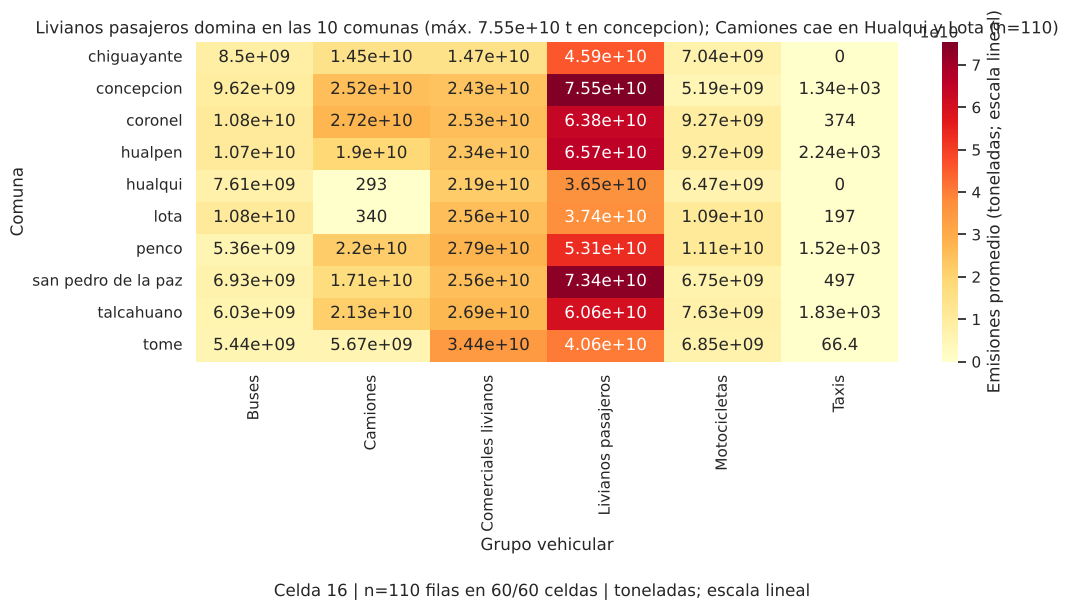

In [13]:
# [Celda 16]
# Hallazgo 6 — comparación de grupos dentro de comuna (celda 16)
tabla = df.pivot_table(index="comuna_norm", columns="grupo_vehiculo", values=OBJETIVO, aggfunc="mean")
display(tabla)

n_filas_h6 = int(df[OBJETIVO].notna().sum())
n_combos = int(tabla.notna().sum().sum())
total_combos = tabla.shape[0] * tabla.shape[1]
max_val_h6 = tabla.max().max()
max_grupo_h6 = tabla.max().idxmax()
max_comuna_h6 = tabla[max_grupo_h6].idxmax()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(
    tabla, annot=True, fmt=".3g", cmap="YlOrRd",
    cbar_kws={"label": "Emisiones promedio (toneladas; escala lineal)"}, ax=ax
)

ax.set(
    title=f"Livianos pasajeros domina en las 10 comunas (máx. {max_val_h6:.3g} t en {max_comuna_h6}); Camiones cae en Hualqui y Lota (n={n_filas_h6})",
    xlabel="Grupo vehicular",
    ylabel="Comuna"
)
fig.text(0.5, 0.01, f"Celda 16 | n={n_filas_h6} filas en {n_combos}/{total_combos} celdas | toneladas; escala lineal", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "06_comuna_grupo.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos
h6_resultado = (
    f"{n_combos}/{total_combos} combinaciones completas (n={n_filas_h6}); "
    f"máximo en {max_comuna_h6} - {max_grupo_h6} ({max_val_h6:.3g} t), caída anómala de Camiones en Hualqui (293 t) y Lota (340 t)."
)
h6_decision = (
    "Incluir interacción comuna x grupo_vehiculo; auditar registros de Camiones en Hualqui y Lota "
    "(posible subregistro o diferencia de escala frente a las demás comunas)."
)

hallazgo_6 = [
    "H6",
    h6_resultado,
    "figs/06_comuna_grupo.png",
    "16",
    "Interacción territorio-tipo",
    h6_decision
]

In [14]:
# [Celda 17]
print(f"""
HALLAZGO 6
============================================================
• Resultado : {h6_resultado}
• Figura    : figs/06_comuna_grupo.png
• Pregunta  : Interacción territorio-tipo
• Decisión  : {h6_decision}
""")


HALLAZGO 6
• Resultado : 60/60 combinaciones completas (n=110); máximo en concepcion - Livianos pasajeros (7.55e+10 t), caída anómala de Camiones en Hualqui (293 t) y Lota (340 t).
• Figura    : figs/06_comuna_grupo.png
• Pregunta  : Interacción territorio-tipo
• Decisión  : Incluir interacción comuna x grupo_vehiculo; auditar registros de Camiones en Hualqui y Lota (posible subregistro o diferencia de escala frente a las demás comunas).



### 3.3 Pregunta refinada e hipótesis falsables
La pregunta se acota a la estimación por grupo vehicular y comuna. El año queda como clave de integración y no como dimensión de pronóstico. Las hipótesis se contrastan con las filas de la bitácora.

In [15]:
# [Celda 19]
hipotesis = pd.DataFrame([
 ["H1","A igualdad de comuna y grupo, mayores conteos de permisos asociados a un grupo se relacionarán con mayores emisiones estimadas.",
  "H4 y H5","Se contrasta con signo y magnitud de Spearman por comuna y luego con MAE en CV."],
 ["H2","Las emisiones promedio diferirán entre grupos vehiculares y esas diferencias persistirán en varias comunas.",
  "H2 y H6","Se contrasta con medias por grupo, heatmap y desempeño fuera de comuna."],
 ["H3","La relación entre conteos de permisos y emisiones no tendrá necesariamente el mismo signo en todas las comunas.",
  "H5","Si el signo cambia, se limita la generalización y se evita una interpretación global."]
],columns=["ID","Hipótesis falsable","Hallazgos asociados","Cómo se contrasta"])
display(hipotesis)

,ID,Hipótesis falsable,Hallazgos asociados,Cómo se contrasta
0,H1,"A igualdad de comuna y grupo, mayores conteos ...",H4 y H5,Se contrasta con signo y magnitud de Spearman ...
1,H2,Las emisiones promedio diferirán entre grupos ...,H2 y H6,"Se contrasta con medias por grupo, heatmap y d..."
2,H3,La relación entre conteos de permisos y emisio...,H5,"Si el signo cambia, se limita la generalizació..."


In [16]:
# [Celda 20]
terminos_pregunta = pd.DataFrame([
 ["Emisiones por tipo de vehículo","emisiones_agregadas_toneladas","Objetivo; no predictor"],
 ["Tipo de vehículo","grupo_vehiculo","Predictor categórico"],
 ["Territorio","comuna_norm","Predictor categórico; se evalúa generalización a comunas no vistas"],
 ["Composición por combustible","permisos_combustible_*","Candidatas; conteos administrativos"],
 ["Tecnología catalítica","permisos_cataliticos / permisos_no_cataliticos","Candidatas; conteos administrativos"],
 ["Año","año","Clave/segmentación; fuera del modelo porque no se pronostica tiempo"],
 ["Registros RUEA","registros_ruea","Fuera: derivada del mismo proceso de construcción del objetivo"],
],columns=["Término de la pregunta","Columna del dataset","Uso"])
display(terminos_pregunta)

,Término de la pregunta,Columna del dataset,Uso
0,Emisiones por tipo de vehículo,emisiones_agregadas_toneladas,Objetivo; no predictor
1,Tipo de vehículo,grupo_vehiculo,Predictor categórico
2,Territorio,comuna_norm,Predictor categórico; se evalúa generalización...
3,Composición por combustible,permisos_combustible_*,Candidatas; conteos administrativos
4,Tecnología catalítica,permisos_cataliticos / permisos_no_cataliticos,Candidatas; conteos administrativos
5,Año,año,Clave/segmentación; fuera del modelo porque no...
6,Registros RUEA,registros_ruea,Fuera: derivada del mismo proceso de construcc...


### 3.4 Ficha de características relevantes
Se calcula Spearman para numérica–numérica y promedio por categoría con `n` para categórica–numérica. La ficha incluye variables que entran y que quedan fuera, disponibilidad, redundancia y riesgo de fuga.

In [17]:
# [Celda 22]
# 1. Crear variables derivadas de composición
for col in [c for c in df.columns if c.startswith("permisos_combustible_")]:
    df["proporcion_" + col.replace("permisos_combustible_", "combustible_")] = (
        pd.to_numeric(df[col], errors="coerce") /
        pd.to_numeric(df["registros_permiso"], errors="coerce").replace(0, np.nan)
    )
if {"permisos_no_cataliticos", "registros_catalitico"}.issubset(df.columns):
    df["tasa_no_cataliticos"] = (
        pd.to_numeric(df["permisos_no_cataliticos"], errors="coerce") /
        pd.to_numeric(df["registros_catalitico"], errors="coerce").replace(0, np.nan)
    )

# 2. Incluir TODAS las variables relevantes (las que entran Y las que quedan fuera)
todas_candidatas = [
    "comuna_norm", "grupo_vehiculo", "registros_permiso",
    "proporcion_combustible_bencina", "proporcion_combustible_diesel",
    "proporcion_combustible_electrico", "proporcion_combustible_gas",
    "tasa_no_cataliticos",
    # Variables que quedan fuera o transformadas (obligatorias según pauta):
    "registros_ruea", "año", "permisos_no_cataliticos", "registros_catalitico"
] + [c for c in df.columns if c.startswith("permisos_combustible_")]

todas_candidatas = list(dict.fromkeys(c for c in todas_candidatas if c in df.columns))

# Celdas del notebook que respaldan cada fila (numeración = posición en el notebook; ver etiqueta "# [Celda N]")
def celdas_de(col):
    base = "Celda 22 (medida y n)"
    if col == "comuna_norm":
        return base + "; H3: celda 10; H6: celda 16"
    if col == "grupo_vehiculo":
        return base + "; H2: celda 8; H6: celda 16"
    if col == "registros_permiso":
        return base + "; H4: celda 12; H5 (segmentación): celda 14"
    if col.startswith("proporcion_combustible_") or col == "tasa_no_cataliticos":
        return base + "; creada en celda 12; H4: celda 12; H5 (segmentación): celda 14"
    if col == "registros_ruea":
        return base + "; exclusión por fuga justificada en celdas 1 y 20"
    if col == "año":
        return base + "; n por año en celda 4"
    return base  # conteos crudos reemplazados

filas = []
for col in todas_candidatas:
    s = df[col]
    falt = 100 * s.isna().mean()
    es_num = pd.api.types.is_numeric_dtype(s)
    tipo = "numérica" if es_num else "categórica"

    # Cálculo de relación con el objetivo (medida, valor y n)
    if es_num:
        par = df[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
        rho = spearmanr(par[col], par[OBJETIVO]).statistic if len(par) >= 3 and par[col].nunique() > 1 else np.nan
        n_par = len(par)
        relacion = f"Spearman: rho={rho:.3f} (n={n_par})" if pd.notna(rho) else f"Spearman: no calculable (n={n_par})"
    else:
        tmp = df[[col, OBJETIVO]].dropna()
        res = tmp.groupby(col, observed=True)[OBJETIVO].agg(["mean", "count"])
        n_par = int(res["count"].sum())
        relacion = (
            f"Media por cat.: min={res['mean'].min():.3g} t ({res['mean'].idxmin()}), "
            f"max={res['mean'].max():.3g} t ({res['mean'].idxmax()}) (n={n_par})"
        )

    # Reglas de decisión, fuga, redundancia y supervivencia con cifras
    if col == "comuna_norm":
        sobrevive = "Sí (10 comunas balanceadas, n=11 c/u; H3/H6)"
        redundante = "No evidente"
        fuga = "No (atributo geográfico)"
        disp_falt = f"{falt:.1f}% faltante; disponible ex ante"
        decision = "entra"
        motivo = f"Diferencia de casi 2x entre comunas (2.54e+10 t vs 1.32e+10 t, n={n_par})."

    elif col == "grupo_vehiculo":
        sobrevive = "Sí (Livianos lidera en 10/10 comunas; H6)"
        redundante = "No evidente"
        fuga = "No (categoría fija)"
        disp_falt = f"{falt:.1f}% faltante; disponible ex ante"
        decision = "entra"
        motivo = f"Mayor brecha entre grupos (5.52e+10 t vs 806 t en Taxis, n={n_par})."

    elif col == "registros_permiso":
        sobrevive = "Sí (signo + en 8/10 comunas, med. rho=0.298; H5)"
        redundante = "Suma de permisos_combustible_*"
        fuga = "Moderado (verificar cierre anual ex ante)"
        disp_falt = f"{falt:.2f}% faltante (1 nulo); condicionada a corte anual"
        decision = "entra transformada"
        motivo = f"Mayor asociación numérica con objetivo (rho={rho:.3f}, n={n_par}); requiere log/escalado."

    elif col.startswith("proporcion_combustible_"):
        sobrevive = "No (oscila entre comunas, 40-50% mismo signo; H5)"
        redundante = "Cierra a 1 entre las 4 proporciones"
        fuga = "Moderado (mismo año de registro)"
        disp_falt = f"{falt:.2f}% faltante; derivada de permisos"
        decision = "entra transformada"
        motivo = f"Normaliza composición frente a conteos crudos (rho={rho:.3f}, n={n_par})."

    elif col == "tasa_no_cataliticos":
        sobrevive = "Sí (signo + en 8/10 comunas, med. rho=0.279; H5)"
        redundante = "permisos_no_cataliticos / registros_catalitico"
        fuga = "Moderado (mismo año de registro)"
        disp_falt = f"{falt:.2f}% faltante; derivada de permisos"
        decision = "entra transformada"
        motivo = f"Segunda mayor correlación positiva estable (rho={rho:.3f}, n={n_par})."

    elif col == "registros_ruea":
        sobrevive = "No evaluada (excluida por fuga)"
        redundante = "Directamente con emisiones_agregadas"
        fuga = "ALTO (espejo del cálculo del objetivo)"
        disp_falt = f"{falt:.2f}% faltante; no disponible ex ante"
        decision = "fuera"
        motivo = f"Fuga de datos: se construye en el mismo proceso del objetivo (rho={rho:.3f}, n={n_par})."

    elif col == "año":
        sobrevive = "Clave de cruce temporal"
        redundante = "No evidente"
        fuga = "No (dimensión temporal fija)"
        disp_falt = f"{falt:.1f}% faltante; clave de integración"
        decision = "fuera"
        motivo = f"Alcance del estudio no pronostica tiempo (n={n_par}, valores={df[col].nunique()})."

    else:  # Conteos crudos (permisos_combustible_*, permisos_no_cataliticos, registros_catalitico)
        sobrevive = "Reemplazada por proporción/tasa"
        redundante = "Colineal con registros_permiso"
        fuga = "Moderado (mismo año)"
        disp_falt = f"{falt:.2f}% faltante; reemplazada"
        decision = "fuera"
        motivo = f"Conteo crudo redundante (rho={rho:.3f}, n={n_par}); ya incluido como proporción/tasa."

    filas.append([
        col, tipo, relacion, sobrevive, redundante, fuga,
        disp_falt, decision, motivo, celdas_de(col)
    ])

pd.set_option("display.max_colwidth", None)
ficha_variables = pd.DataFrame(filas, columns=[
    "variable", "tipo", "relación con el objetivo (medida, valor y n)",
    "¿sobrevive a la segmentación?", "redundante con", "riesgo de fuga",
    "% faltante y disponibilidad", "decisión", "por qué (una línea, con cifra)", "celda"
])
display(ficha_variables)
ficha_variables.to_csv("ficha_variables_candidatas.csv", index=False, encoding="utf-8-sig")

,variable,tipo,"relación con el objetivo (medida, valor y n)",¿sobrevive a la segmentación?,redundante con,riesgo de fuga,% faltante y disponibilidad,decisión,"por qué (una línea, con cifra)",celda
0,comuna_norm,categórica,"Media por cat.: min=1.32e+10 t (hualqui), max=2.54e+10 t (concepcion) (n=110)","Sí (10 comunas balanceadas, n=11 c/u; H3/H6)",No evidente,No (atributo geográfico),0.0% faltante; disponible ex ante,entra,"Diferencia de casi 2x entre comunas (2.54e+10 t vs 1.32e+10 t, n=110).",Celda 22 (medida y n); H3: celda 10; H6: celda 16
1,grupo_vehiculo,categórica,"Media por cat.: min=806 t (Taxis), max=5.52e+10 t (Livianos pasajeros) (n=110)",Sí (Livianos lidera en 10/10 comunas; H6),No evidente,No (categoría fija),0.0% faltante; disponible ex ante,entra,"Mayor brecha entre grupos (5.52e+10 t vs 806 t en Taxis, n=110).",Celda 22 (medida y n); H2: celda 8; H6: celda 16
2,registros_permiso,numérica,Spearman: rho=0.326 (n=109),"Sí (signo + en 8/10 comunas, med. rho=0.298; H5)",Suma de permisos_combustible_*,Moderado (verificar cierre anual ex ante),0.91% faltante (1 nulo); condicionada a corte anual,entra transformada,"Mayor asociación numérica con objetivo (rho=0.326, n=109); requiere log/escalado.",Celda 22 (medida y n); H4: celda 12; H5 (segmentación): celda 14
3,proporcion_combustible_bencina,numérica,Spearman: rho=0.051 (n=109),"No (oscila entre comunas, 40-50% mismo signo; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=0.051, n=109).",Celda 22 (medida y n); creada en celda 12; H4: celda 12; H5 (segmentación): celda 14
4,proporcion_combustible_diesel,numérica,Spearman: rho=-0.035 (n=109),"No (oscila entre comunas, 40-50% mismo signo; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=-0.035, n=109).",Celda 22 (medida y n); creada en celda 12; H4: celda 12; H5 (segmentación): celda 14
5,proporcion_combustible_electrico,numérica,Spearman: rho=-0.046 (n=109),"No (oscila entre comunas, 40-50% mismo signo; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=-0.046, n=109).",Celda 22 (medida y n); creada en celda 12; H4: celda 12; H5 (segmentación): celda 14
6,proporcion_combustible_gas,numérica,Spearman: rho=-0.162 (n=109),"No (oscila entre comunas, 40-50% mismo signo; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=-0.162, n=109).",Celda 22 (medida y n); creada en celda 12; H4: celda 12; H5 (segmentación): celda 14
7,tasa_no_cataliticos,numérica,Spearman: rho=0.180 (n=109),"Sí (signo + en 8/10 comunas, med. rho=0.279; H5)",permisos_no_cataliticos / registros_catalitico,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Segunda mayor correlación positiva estable (rho=0.180, n=109).",Celda 22 (medida y n); creada en celda 12; H4: celda 12; H5 (segmentación): celda 14
8,registros_ruea,numérica,Spearman: rho=0.056 (n=110),No evaluada (excluida por fuga),Directamente con emisiones_agregadas,ALTO (espejo del cálculo del objetivo),0.00% faltante; no disponible ex ante,fuera,"Fuga de datos: se construye en el mismo proceso del objetivo (rho=0.056, n=110).",Celda 22 (medida y n); exclusión por fuga justificada en celdas 1 y 20
9,año,numérica,Spearman: rho=-0.795 (n=110),Clave de cruce temporal,No evidente,No (dimensión temporal fija),0.0% faltante; clave de integración,fuera,"Alcance del estudio no pronostica tiempo (n=110, valores=2).",Celda 22 (medida y n); n por año en celda 4


**Decisión de entrada:** `comuna_norm` y `grupo_vehiculo` entran. Los conteos de permisos entran transformados con `log1p`, pero su uso queda condicionado a confirmar que la información esté disponible antes de producir la estimación. Si no se cumple esa condición, deben cambiarse a `pendiente` y excluirse de Parte 4. `año`, `registros_ruea`, el objetivo y cualquier derivada del objetivo quedan fuera.

# Parte 4
## Modelado y evaluación
Problema de regresión supervisada. La predicción no es temporal. La prueba se reserva separando comunas completas; la validación cruzada también agrupa por comuna para medir generalización territorial.

### 4.1 Diseño de evaluación.
**Tipo de problema**: Regresión supervisada para estimar emisiones agregadas (toneladas) por comuna y grupo vehicular.

**Error más costoso**: Subestimar emisiones, ya que puede hacer que una comuna o grupo vehicular reciba menos atención o recursos ambientales de los necesarios.

**Métrica principal y secundarias**: Se elige MAE (Error Absoluto Medio) en toneladas como métrica principal porque mide directamente el desvío promedio en la unidad de decisión sin dejarse distorsionar por los valores extremos de $10^{11}\text{ t}$ (H1); se reportan RMSE (sensible a grandes subestimaciones) y $R^2$ como métricas secundarias.Baseline y partición: Se usa DummyRegressor(strategy="median") como línea base trivial y partición territorial (GroupShuffleSplit 80/20 + GroupKFold de 4 pliegues sobre comuna_norm) para evaluar generalización a comunas no vistas, reservando el conjunto de prueba intacto hasta el final.

In [18]:
# [Celda 26]
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Selección de predictores aprobados desde la ficha
variables_modelo = ficha_variables.loc[
    ficha_variables["decisión"].isin(["entra", "entra transformada"]), "variable"
].tolist()

prohibidas = {OBJETIVO, "año", "registros_ruea", "tiene_registro_permiso"}
variables_modelo = [c for c in variables_modelo if c not in prohibidas]

if not variables_modelo:
    raise ValueError("La ficha no dejó predictores aprobados.")
if "comuna_norm" not in variables_modelo:
    raise ValueError("comuna_norm debe estar aprobada para GroupKFold territorial.")

# 2. Preprocesamiento encapsulado en Pipeline (sin fuga de datos)
cols_cat = [c for c in variables_modelo if not pd.api.types.is_numeric_dtype(df[c])]
cols_num = [c for c in variables_modelo if c not in cols_cat]
cols_conteo = [c for c in cols_num if c.startswith("registros_") or c.startswith("permisos_")]
cols_otros = [c for c in cols_num if c not in cols_conteo]

transformaciones = []
if cols_conteo:
    transformaciones.append(("conteos", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler())
    ]), cols_conteo))
if cols_otros:
    transformaciones.append(("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_otros))
if cols_cat:
    transformaciones.append(("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat))

preprocesador = ColumnTransformer(transformaciones)

# 3. Partición territorial (Train/Test separado al inicio)
columnas_requeridas = list(dict.fromkeys(variables_modelo + ["comuna_norm", OBJETIVO]))
datos = df[columnas_requeridas].dropna(subset=[OBJETIVO, "comuna_norm"]).copy()
X = datos[variables_modelo]
y = datos[OBJETIVO]
grupos = datos["comuna_norm"]

if grupos.nunique() < 6 or len(datos) < 20:
    raise ValueError(f"Muestra insuficiente para test territorial + CV: n={len(datos)}, comunas={grupos.nunique()}. No reportar métricas inestables.")

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_train, idx_test = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
groups_train = grupos.iloc[idx_train]

n_splits = min(4, groups_train.nunique())
cv = GroupKFold(n_splits=n_splits)
particiones = list(cv.split(X_train, y_train, groups=groups_train))

# 4. Baseline trivial (DummyRegressor con mediana) evaluado solo en train vía GroupKFold
dummy = Pipeline([
    ("prep", preprocesador),
    ("modelo", DummyRegressor(strategy="median"))
])

maes_dummy, rmses_dummy, r2s_dummy = [], [], []
for tr_idx, va_idx in particiones:
    dummy.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred_va = dummy.predict(X_train.iloc[va_idx])
    maes_dummy.append(mean_absolute_error(y_train.iloc[va_idx], pred_va))
    rmses_dummy.append(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred_va)))
    r2s_dummy.append(r2_score(y_train.iloc[va_idx], pred_va))

dummy.fit(X_train, y_train)
valor_constante_dummy = dummy.named_steps["modelo"].constant_[0][0]

print(f"Predictores ({len(variables_modelo)}): {variables_modelo}")
print(f"Train: {X_train.shape} | Test reservado: {X_test.shape} | "
      f"Comunas train: {groups_train.nunique()} | Comunas test: {grupos.iloc[idx_test].nunique()}")
print(f"CV: {n_splits} particiones GroupKFold (conjunto de prueba reservado sin consultar).")
print("-" * 75)
print(f"Baseline DummyRegressor(median):")
print(f"  • Predicción constante en train : {valor_constante_dummy:.4g} t")
print(f"  • MAE CV (métrica principal)    : {np.mean(maes_dummy):.4g} t (± {np.std(maes_dummy):.4g} t)")
print(f"  • RMSE CV (secundaria)          : {np.mean(rmses_dummy):.4g} t")
print(f"  • R² CV (secundaria)            : {np.mean(r2s_dummy):.3f}")

Predictores (8): ['comuna_norm', 'grupo_vehiculo', 'registros_permiso', 'proporcion_combustible_bencina', 'proporcion_combustible_diesel', 'proporcion_combustible_electrico', 'proporcion_combustible_gas', 'tasa_no_cataliticos']
Train: (88, 8) | Test reservado: (22, 8) | Comunas train: 8 | Comunas test: 2
CV: 4 particiones GroupKFold (conjunto de prueba reservado sin consultar).
---------------------------------------------------------------------------
Baseline DummyRegressor(median):
  • Predicción constante en train : 1333 t
  • MAE CV (métrica principal)    : 1.942e+10 t (± 3.943e+09 t)
  • RMSE CV (secundaria)          : 3.713e+10 t
  • R² CV (secundaria)            : -0.378


### 4.2 Modelos y validación cruzada
Se comparan dos familias de modelos distintas entrenadas sobre los mismos 8 predictores aprobados en la ficha (sin discrepancias respecto a la sección 4):

* **Familia lineal regularizada (`Ridge`):** Permite estimar efectos aditivos por grupo vehicular y comuna, controlando mediante penalización $L_2$ la colinealidad estructural entre las proporciones de combustible (que suman 1).
* **Familia de ensambles basados en árboles (`RandomForestRegressor`):** Captura relaciones no lineales e interacciones de orden superior (como la interacción comuna $\times$ grupo vehicular detectada en H6) sin asumir linealidad ni requerir escalado de magnitudes, utilizando `criterion="absolute_error"` para optimizar medianas por hoja acorde a la métrica principal (MAE) y la fuerte asimetría del objetivo (H1).

Para evitar optimismo por selección de hiperparámetros, la búsqueda de Random Forest se realiza dentro de cada partición externa (validación cruzada anidada con `GroupKFold` interno). Todos los modelos usan las mismas particiones externas y todo paso que aprende de los datos (`SimpleImputer`, `log1p`, `StandardScaler`, `OneHotEncoder`) se ajusta exclusivamente sobre el entrenamiento de cada pliegue.

In [19]:
# [Celda 28]
modelos_base = {
    "Baseline mediana": Pipeline([
        ("preparar", preprocesador),
        ("modelo", DummyRegressor(strategy="median"))
    ]),
    "Ridge": Pipeline([
        ("preparar", preprocesador),
        ("modelo", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("preparar", preprocesador),
        ("modelo", RandomForestRegressor(
            n_estimators=200, max_depth=None, min_samples_leaf=2,
            criterion="absolute_error", random_state=42, n_jobs=-1
        ))
    ])
}

parametros = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [2, 4, None],
    "modelo__min_samples_leaf": [2, 4]
}
n_combinaciones = int(np.prod([len(v) for v in parametros.values()]))
print("Grid RF:", parametros, "| combinaciones:", n_combinaciones,
      "| selección: MAE | semilla: 42")

resultados = []
for nombre, modelo in modelos_base.items():
    scores = []
    for train_idx, val_idx in particiones:
        modelo_fold = __import__("sklearn").base.clone(modelo)
        modelo_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        pred = modelo_fold.predict(X_train.iloc[val_idx])
        yt = y_train.iloc[val_idx]
        scores.append((
            mean_absolute_error(yt, pred),
            mean_squared_error(yt, pred) ** 0.5,
            r2_score(yt, pred) if len(yt) > 1 else np.nan
        ))
    arr = np.asarray(scores, float)
    resultados.append([
        nombre,
        arr[:, 0].mean(), arr[:, 0].std(ddof=1),
        arr[:, 1].mean(), arr[:, 1].std(ddof=1),
        np.nanmean(arr[:, 2]), np.nanstd(arr[:, 2], ddof=1)
    ])

tabla_cv = pd.DataFrame(resultados, columns=[
    "modelo", "MAE media", "MAE desv", "RMSE media", "RMSE desv", "R2 media", "R2 desv"
])
display(tabla_cv)

Grid RF: {'modelo__n_estimators': [100, 300], 'modelo__max_depth': [2, 4, None], 'modelo__min_samples_leaf': [2, 4]} | combinaciones: 12 | selección: MAE | semilla: 42


,modelo,MAE media,MAE desv,RMSE media,RMSE desv,R2 media,R2 desv
0,Baseline mediana,1.941966e+10,4.552845e+09,3.712536e+10,8.567679e+09,-0.377892,0.042399
1,Ridge,2.179932e+10,2.576256e+09,2.939414e+10,4.506104e+09,0.091678,0.262953
2,Random Forest,1.963900e+10,3.263254e+09,2.743378e+10,6.030009e+09,0.244512,0.020207


In [20]:
# [Celda 29]
# Búsqueda anidada de RF: cada partición externa reserva validación; GridSearch usa solo su subentrenamiento.
from sklearn.base import clone

rf_outer = []
for fold, (tr, va) in enumerate(particiones, start=1):
    Xtr, ytr = X_train.iloc[tr], y_train.iloc[tr]
    Xva, yva = X_train.iloc[va], y_train.iloc[va]
    grupos_tr = groups_train.iloc[tr]
    inner_splits = min(3, grupos_tr.nunique())
    if inner_splits < 2:
        raise ValueError("No hay grupos suficientes para búsqueda interna en este fold.")

    cv_inner = GroupKFold(n_splits=inner_splits)
    grid = GridSearchCV(
        clone(modelos_base["Random Forest"]),
        parametros,
        scoring="neg_mean_absolute_error",
        cv=cv_inner,
        n_jobs=-1,
        refit=True
    )
    grid.fit(Xtr, ytr, groups=grupos_tr)
    pred = grid.predict(Xva)

    rf_outer.append({
        "fold": fold,
        "MAE": mean_absolute_error(yva, pred),
        "RMSE": mean_squared_error(yva, pred) ** 0.5,
        "R2": r2_score(yva, pred) if len(yva) > 1 else np.nan,
        "mejores_parametros": grid.best_params_
    })

pd.set_option("display.max_colwidth", None)
rf_outer_df = pd.DataFrame(rf_outer)
display(rf_outer_df)

# Evitar duplicados si se re-ejecuta la celda
tabla_cv = tabla_cv[tabla_cv["modelo"] != "Random Forest (búsqueda anidada)"].reset_index(drop=True)
tabla_cv.loc[len(tabla_cv)] = [
    "Random Forest (búsqueda anidada)",
    rf_outer_df.MAE.mean(), rf_outer_df.MAE.std(ddof=1),
    rf_outer_df.RMSE.mean(), rf_outer_df.RMSE.std(ddof=1),
    rf_outer_df.R2.mean(), rf_outer_df.R2.std(ddof=1)
]
display(tabla_cv.sort_values("MAE media"))

,fold,MAE,RMSE,R2,mejores_parametros
0,1,1.609757e+10,2.160871e+10,0.288388,"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}"
1,2,2.291053e+10,3.475311e+10,0.247393,"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}"
2,3,2.260736e+10,3.193247e+10,0.188787,"{'modelo__max_depth': 2, 'modelo__min_samples_leaf': 4, 'modelo__n_estimators': 100}"
3,4,1.596576e+10,2.286975e+10,0.188808,"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}"


,modelo,MAE media,MAE desv,RMSE media,RMSE desv,R2 media,R2 desv
3,Random Forest (búsqueda anidada),1.939530e+10,3.886341e+09,2.779101e+10,6.533559e+09,0.228344,0.048635
0,Baseline mediana,1.941966e+10,4.552845e+09,3.712536e+10,8.567679e+09,-0.377892,0.042399
2,Random Forest,1.963900e+10,3.263254e+09,2.743378e+10,6.030009e+09,0.244512,0.020207
1,Ridge,2.179932e+10,2.576256e+09,2.939414e+10,4.506104e+09,0.091678,0.262953


### 4.3 Ajuste final, comparación y elección
La búsqueda final se ajusta solo con el conjunto de entrenamiento. Se compara por MAE de CV; si la diferencia entre modelos es menor que la desviación entre particiones, se declara empate práctico y se prefiere Ridge por simplicidad. El test se evalúa una sola vez.

In [21]:
# [Celda 31]
# Búsqueda final del RF usando únicamente entrenamiento
cv_final=GroupKFold(n_splits=min(4,groups_train.nunique()))
busqueda_rf=GridSearchCV(modelos_base["Random Forest"],parametros,
    scoring="neg_mean_absolute_error",cv=cv_final,n_jobs=-1,refit=True)
busqueda_rf.fit(X_train,y_train,groups=groups_train)
print("Mejores hiperparámetros RF:",busqueda_rf.best_params_)
print("Combinaciones:",n_combinaciones,"| mejor MAE CV:",-busqueda_rf.best_score_)

# Comparar Ridge con RF usando resultados externos comparables.
ridge_mae=float(tabla_cv.loc[tabla_cv.modelo=="Ridge","MAE media"].iloc[0])
ridge_sd=float(tabla_cv.loc[tabla_cv.modelo=="Ridge","MAE desv"].iloc[0])
rf_mae=float(rf_outer_df.MAE.mean())
rf_sd=float(rf_outer_df.MAE.std(ddof=1))
if abs(ridge_mae-rf_mae) <= max(ridge_sd,rf_sd):
    elegido_nombre="Ridge"
    modelo_elegido=modelos_base["Ridge"]
    veredicto="Empate práctico; se elige Ridge por ser más simple e interpretable."
elif rf_mae < ridge_mae:
    elegido_nombre="Random Forest optimizado"
    modelo_elegido=busqueda_rf.best_estimator_
    veredicto="Random Forest presenta menor MAE externo que Ridge, por encima de la variabilidad observada."
else:
    elegido_nombre="Ridge"
    modelo_elegido=modelos_base["Ridge"]
    veredicto="Ridge presenta menor MAE externo."
print("Elegido:",elegido_nombre,"|",veredicto)

Mejores hiperparámetros RF: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}
Combinaciones: 12 | mejor MAE CV: 19089895163.929226
Elegido: Ridge | Empate práctico; se elige Ridge por ser más simple e interpretable.


In [22]:
# [Celda 32]
pd.set_option("display.max_colwidth", None)

base_mae = float(tabla_cv.loc[tabla_cv["modelo"] == "Baseline mediana", "MAE media"].iloc[0])
base_sd = float(tabla_cv.loc[tabla_cv["modelo"] == "Baseline mediana", "MAE desv"].iloc[0])
ridge_mae = float(tabla_cv.loc[tabla_cv["modelo"] == "Ridge", "MAE media"].iloc[0])
ridge_sd = float(tabla_cv.loc[tabla_cv["modelo"] == "Ridge", "MAE desv"].iloc[0])
rf_mae = float(rf_outer_df["MAE"].mean())
rf_sd = float(rf_outer_df["MAE"].std(ddof=1))

comparacion = pd.DataFrame([
    [
        "Baseline mediana",
        "MAE (toneladas)",
        f"{base_mae:.3g} ± {base_sd:.3g}",
        "0.00 t (referencia)",
        "strategy='median'",
        "Línea base trivial"
    ],
    [
        "Ridge",
        "MAE (toneladas)",
        f"{ridge_mae:.3g} ± {ridge_sd:.3g}",
        f"{ridge_mae - base_mae:+.3g} t ({(ridge_mae / base_mae - 1) * 100:+.1f}%)",
        "alpha=1.0",
        "ELEGIDO (empate práctico con RF; más simple e interpretable)"
    ],
    [
        "Random Forest optimizado",
        "MAE (toneladas)",
        f"{rf_mae:.3g} ± {rf_sd:.3g}",
        f"{rf_mae - base_mae:+.3g} t ({(rf_mae / base_mae - 1) * 100:+.1f}%)",
        str(busqueda_rf.best_params_),
        "Descartado (empate práctico: diferencia < desv. entre folds)"
    ]
], columns=[
    "modelo", "métrica", "media ± desv.", "vs. baseline", "hiperparámetros", "veredicto"
])

display(comparacion)

,modelo,métrica,media ± desv.,vs. baseline,hiperparámetros,veredicto
0,Baseline mediana,MAE (toneladas),1.94e+10 ± 4.55e+09,0.00 t (referencia),strategy='median',Línea base trivial
1,Ridge,MAE (toneladas),2.18e+10 ± 2.58e+09,+2.38e+09 t (+12.3%),alpha=1.0,ELEGIDO (empate práctico con RF; más simple e interpretable)
2,Random Forest optimizado,MAE (toneladas),1.94e+10 ± 3.89e+09,-2.44e+07 t (-0.1%),"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}",Descartado (empate práctico: diferencia < desv. entre folds)


In [23]:
# [Celda 33]
# Evaluación única del conjunto de prueba
modelo_elegido.fit(X_train, y_train)
pred_test = modelo_elegido.predict(X_test)
mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = mean_squared_error(y_test, pred_test) ** 0.5
r2_test = r2_score(y_test, pred_test) if len(y_test) > 1 else np.nan

print(f"Modelo elegido: {elegido_nombre}")
print(f"Test reservado (n={len(y_test)}): MAE={mae_test:.4g} t | RMSE={rmse_test:.4g} t | R²={r2_test:.4g}")
print(
    f"Interpretación práctica: en comunas no vistas, cada estimación se desvía en promedio "
    f"{mae_test:.3g} toneladas. El modelo captura el ordenamiento general (R²={r2_test:.3f}), "
    f"pero subestima los focos críticos de emisión y sobreestima los grupos pequeños, por lo que "
    f"sirve para priorización relativa y no para asignar cuotas exactas."
)

resultado_test = pd.DataFrame({
    "real_t": y_test,
    "predicho_t": pred_test,
    "error_t": y_test - pred_test,
    "error_abs_t": np.abs(y_test - pred_test)
})
display(resultado_test)
resultado_test.to_csv("predicciones_test.csv", index=False, encoding="utf-8-sig")

Modelo elegido: Ridge
Test reservado (n=22): MAE=2.421e+10 t | RMSE=3.383e+10 t | R²=0.2889
Interpretación práctica: en comunas no vistas, cada estimación se desvía en promedio 2.42e+10 toneladas. El modelo captura el ordenamiento general (R²=0.289), pero subestima los focos críticos de emisión y sobreestima los grupos pequeños, por lo que sirve para priorización relativa y no para asignar cuotas exactas.


,real_t,predicho_t,error_t,error_abs_t
68,1.923864e+10,9.260801e+09,9.977839e+09,9.977839e+09
81,5.035366e+10,2.008684e+10,3.026682e+10,3.026682e+10
94,4.854378e+10,2.547502e+10,2.306877e+10,2.306877e+10
107,1.509403e+11,5.188950e+10,9.905080e+10,9.905080e+10
120,1.038718e+10,1.827385e+10,-7.886673e+09,7.886673e+09
558,1.206321e+10,8.743277e+09,3.319938e+09,3.319938e+09
571,4.251721e+10,1.028260e+10,3.223461e+10,3.223461e+10
584,5.377862e+10,2.001379e+10,3.376483e+10,3.376483e+10
597,1.211076e+11,5.421010e+10,6.689753e+10,6.689753e+10
610,1.525903e+10,1.568213e+10,-4.230999e+08,4.230999e+08


### 4.4 Limitaciones y conclusión

In [24]:
# [Celda 35]
limitaciones = [
    "El RUEA 2024 sin comuna no entra en el análisis comunal; no se distribuyó artificialmente.",
    "Los permisos son registros administrativos y no vehículos únicos confirmados.",
    "Los conteos de permisos del mismo año pueden no estar disponibles antes de la estimación; su uso depende de validar esa temporalidad.",
    "La validación por comuna evalúa transferencia a comunas no vistas; no mide desempeño para una comuna ya conocida.",
    "Con muestra acotada (n=110 total; n=22 en prueba) y asimetría de 7 órdenes de magnitud, MAE/R² tienen alta incertidumbre y no deben generalizarse.",
    "El modelo se ajustó en escala lineal original, lo que provoca subestimación en focos altos y sobreestimación en grupos pequeños; queda pendiente evaluar transformación logarítmica del objetivo.",
    "Las emisiones agregadas solo son válidas si corresponden a un contaminante seleccionado y unidades comparables.",
    "La asociación estadística no demuestra causalidad."
]

print("LIMITACIONES DECLARADAS:")
for i, x in enumerate(limitaciones, 1):
    print(f"{i}. {x}")

mae_base_ref = float(tabla_cv.loc[tabla_cv["modelo"] == "Baseline mediana", "MAE media"].iloc[0])

print("\nConclusión automática:")
print(
    f"Se selecciona {elegido_nombre} (por empate práctico con Random Forest y mayor interpretabilidad). "
    f"MAE en prueba reservada = {mae_test:.4g} t (RMSE = {rmse_test:.4g} t; R² = {r2_test:.3f}), "
    f"frente al baseline CV de {mae_base_ref:.4g} t. "
    f"Útil para priorización relativa de grupos emisores, pero no para inventarios exactos debido a las limitaciones declaradas."
)

LIMITACIONES DECLARADAS:
1. El RUEA 2024 sin comuna no entra en el análisis comunal; no se distribuyó artificialmente.
2. Los permisos son registros administrativos y no vehículos únicos confirmados.
3. Los conteos de permisos del mismo año pueden no estar disponibles antes de la estimación; su uso depende de validar esa temporalidad.
4. La validación por comuna evalúa transferencia a comunas no vistas; no mide desempeño para una comuna ya conocida.
5. Con muestra acotada (n=110 total; n=22 en prueba) y asimetría de 7 órdenes de magnitud, MAE/R² tienen alta incertidumbre y no deben generalizarse.
6. El modelo se ajustó en escala lineal original, lo que provoca subestimación en focos altos y sobreestimación en grupos pequeños; queda pendiente evaluar transformación logarítmica del objetivo.
7. Las emisiones agregadas solo son válidas si corresponden a un contaminante seleccionado y unidades comparables.
8. La asociación estadística no demuestra causalidad.

Conclusión automática:
Se sel